# CameraTrapML — results walkthrough

**Question:** how small can a wildlife species classifier get before it stops being useful?

This notebook walks through every result of the project, straight from the saved result files
(`data/results/*.csv`). It needs **no GPU and no dataset**: sections 1–6 run in a few seconds, so it can be shown live
(the optional demo in section 7 takes a few minutes).
The experiments themselves were produced by `notebooks/colab_run.ipynb` (≈3 h on a Colab GPU) and
`Dockerfile.constrained` (1-core device test).

**How to run:** `uv sync --extra notebook` then `uv run jupyter lab notebooks/results_walkthrough.ipynb`.

| Section | What it shows |
|---|---|
| 1 | What we tested (terms) |
| 2 | The raw result files |
| 3 | Accuracy: shrinking with vs. without retraining |
| 4 | File size |
| 5 | Speed and memory (Colab CPU and a 1-core / 1 GB device) |
| 6 | Which species suffer most |
| 7 | Demo only: the full app on example photos |

## 1. What we tested

- **Quantization** = storing each number (weight) in the model with fewer bits. We tested
  32-bit (full size, `fp32`), 16-bit (`fp16`), 8-bit (`int8`), 4-, 3-, 2-bit, 1.58-bit (each weight is −1, 0 or +1)
  and 1-bit (each weight is −1 or +1).
- **PTQ** (post-training quantization) = round the numbers after training, nothing else.
- **QAT** (quantization-aware training) = round the numbers, then retrain briefly so the model adapts.
- **Model:** MobileNetV2, fine-tuned on animal crops from the ENA24 camera-trap dataset (22 species).
- **Experiment vs. demo:** all measurements below use the dataset's own labeled animal boxes.
  MegaDetector (an off-the-shelf animal finder) is used **only in the demo app** (section 7).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.precision", 3)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "data" / "results"
FIG = ROOT / "data" / "figures" / "mobilenet_v2"

ORDER = ["fp32", "fp16", "int8", "int4", "int3", "int2", "1.58bit", "1bit"]
BITS = {"fp32": 32, "fp16": 16, "int8": 8, "int4": 4, "int3": 3, "int2": 2, "1.58bit": 1.58, "1bit": 1}
print("results folder:", RES)

results folder: /Users/bushb/Downloads/CameraTrapML/data/results


## 2. The raw result files

`run_sweep.py` writes two CSVs per device:

- `mobilenet_v2_<device>_raw.csv`: one row per timing repeat (3 repeats × every model × every batch size).
- `mobilenet_v2_<device>_summary.csv`: mean, std and 95% CI per configuration. This is what we plot.

`data/results/accuracy/` holds one JSON per model with accuracy, F1, confidence intervals and per-species scores.

In [2]:
for f in sorted(RES.glob("*.csv")):
    print(f"{f.name:45s} {len(pd.read_csv(f)):4d} rows")

colab = pd.read_csv(RES / "mobilenet_v2_colab_summary.csv")
device = pd.read_csv(RES / "mobilenet_v2_docker_1cpu_1gb_summary.csv")
colab[["variant", "batch_size", "accuracy", "storage_mb", "latency_ms_per_image_mean",
       "latency_ms_per_image_std", "peak_inference_mb_mean"]].head(8)

mobilenet_v2_colab_raw.csv                     168 rows
mobilenet_v2_colab_summary.csv                  56 rows
mobilenet_v2_docker_1cpu_1gb_raw.csv            48 rows
mobilenet_v2_docker_1cpu_1gb_summary.csv        16 rows


,variant,batch_size,accuracy,storage_mb,latency_ms_per_image_mean,latency_ms_per_image_std,peak_inference_mb_mean
0,1.58bit-ptq,1,0.076,0.669,19.433,0.343,10.152
1,1.58bit-ptq,4,0.076,0.669,12.857,0.149,15.210
2,1.58bit-ptq,8,0.076,0.669,13.383,1.555,22.362
3,1.58bit-ptq,16,0.076,0.669,14.985,0.229,39.293
4,1.58bit-qat,1,0.845,0.669,14.430,0.234,9.956
5,1.58bit-qat,4,0.845,0.669,12.777,0.112,15.635
6,1.58bit-qat,8,0.845,0.669,13.220,2.044,23.167
7,1.58bit-qat,16,0.845,0.669,14.922,0.584,36.512


## 3. Accuracy: shrinking with vs. without retraining

Accuracy = share of test animals (1,475 crops) named correctly. `±` is a 95% confidence interval from
re-sampling the test set 1,000 times.

In [3]:
one = colab[colab.batch_size == 1].drop_duplicates("variant").copy()
one["bits"] = one.level.map(BITS)
one["method"] = one.method.replace("-", "full / fp16")
acc = one.pivot_table(index="level", columns="method", values="accuracy").reindex(ORDER)
acc

method,full / fp16,ptq,qat
level,,,
fp32,0.896,NaN,NaN
fp16,0.896,NaN,NaN
int8,NaN,0.821,0.882
int4,NaN,0.711,0.887
int3,NaN,0.124,0.894
int2,NaN,0.036,0.736
1.58bit,NaN,0.076,0.845
1bit,NaN,0.041,0.798


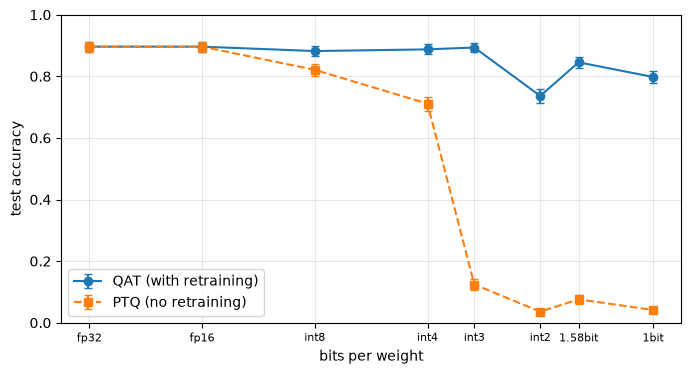

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for method, style, label in [("qat", "o-", "QAT (with retraining)"), ("ptq", "s--", "PTQ (no retraining)")]:
    d = pd.concat([one[one.level.isin(["fp32", "fp16"])], one[one.method == method]]).sort_values("bits", ascending=False)
    ax.errorbar(d.bits, d.accuracy, yerr=1.96 * d.accuracy_std, fmt=style, capsize=3, label=label)
ax.set_xscale("log", base=2); ax.invert_xaxis()
ax.set_xticks(list(BITS.values())); ax.set_xticklabels(list(BITS.keys()), fontsize=8); ax.minorticks_off()
ax.set_ylim(0, 1); ax.set_xlabel("bits per weight"); ax.set_ylabel("test accuracy"); ax.legend(); ax.grid(alpha=.3)
plt.show()

**Finding:** with retraining (QAT), 8-, 4- and 3-bit stay within about one point of the full model (89.6%), and
even 1-bit keeps about 80%. Without retraining (PTQ), 8-bit already drops to 82% and 3-bit and below are
basically guessing. 2-bit QAT dips below 1.58-bit; section 6 shows that it is mostly one species (*Horse*).

## 4. File size

In [5]:
size = one[one.method.isin(["qat", "full / fp16"])].set_index("level").reindex(ORDER)[["storage_mb", "accuracy"]]
size["times_smaller"] = size.storage_mb.iloc[0] / size.storage_mb
size

,storage_mb,accuracy,times_smaller
level,,,
fp32,9.258,0.896,1.000
fp16,4.672,0.896,1.981
int8,2.369,0.882,3.908
int4,1.307,0.887,7.085
int3,1.041,0.894,8.892
int2,0.776,0.736,11.937
1.58bit,0.669,0.845,13.834
1bit,0.510,0.798,18.159


**Finding:** files shrink up to 18× (1-bit). The 3-bit model is about 9× smaller with the same accuracy as the full
model. Sizes are real bit-packed files (`models/*.qpk`), not estimates. They are below the ideal 32/bits because the
first and last layers stay 8-bit.

## 5. Speed and memory

Time per photo on a CPU (lower is better), measured in a fresh program each time and repeated 3 times.
**Colab** is a cloud server CPU; **device** is a Docker container limited to 1 core and 1 GB RAM
(a stand-in for a small field computer).

In [6]:
def speed_table(df, name):
    d = df[(df.batch_size == 1) & df.method.isin(["qat", "-"])].set_index("level").reindex(ORDER)
    return pd.DataFrame({f"{name} ms/photo": d.latency_ms_per_image_mean, f"{name} memory MB": d.peak_inference_mb_mean})

speed = speed_table(colab, "colab").join(speed_table(device, "1-core device"))
speed["speed-up vs fp32 (device)"] = speed.iloc[0, 2] / speed.iloc[:, 2]
speed

,colab ms/photo,colab memory MB,1-core device ms/photo,1-core device memory MB,speed-up vs fp32 (device)
level,,,,,
fp32,43.683,39.794,53.608,41.138,1.000
fp16,841.728,13.910,163.877,28.509,0.327
int8,19.264,10.030,7.050,18.378,7.604
int4,16.138,10.207,7.116,18.346,7.533
int3,19.408,10.172,7.077,18.345,7.575
int2,19.191,10.314,7.123,18.353,7.526
1.58bit,14.430,9.956,7.109,18.331,7.541
1bit,19.339,10.072,7.326,18.348,7.317


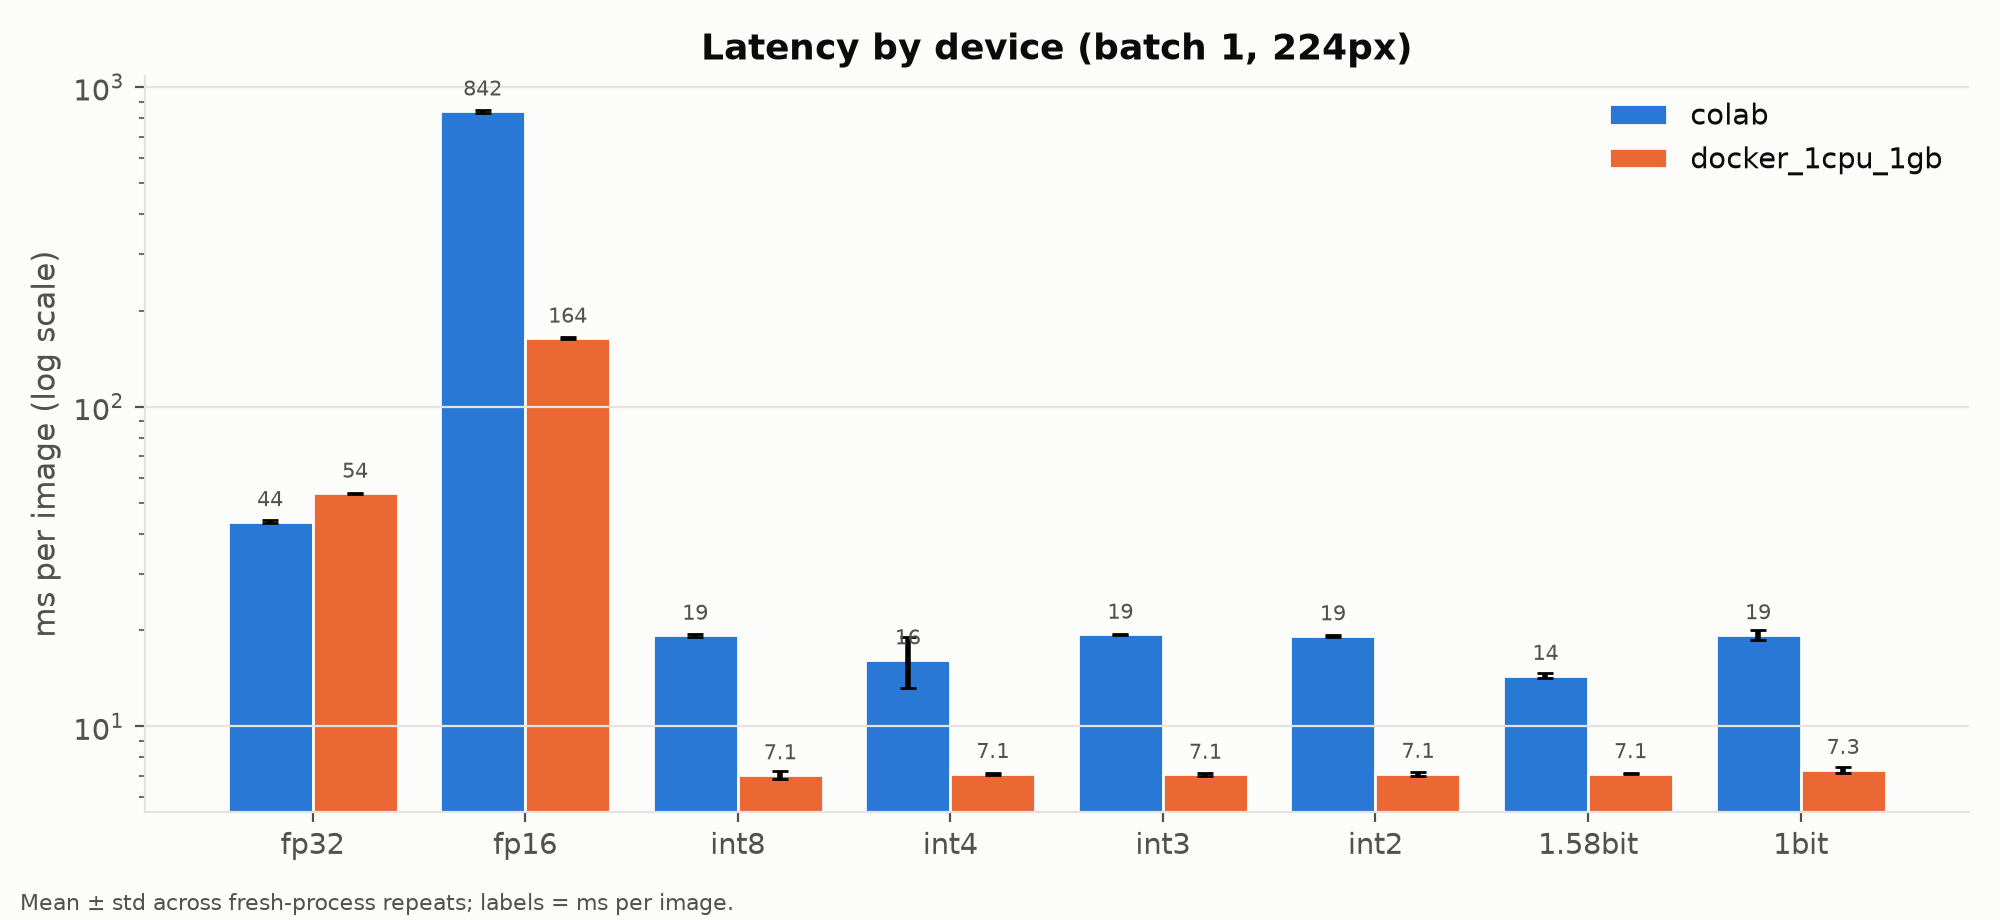

In [7]:
from IPython.display import Image
Image(filename=str(FIG / "11_device_comparison.png"), width=850)

**Finding:** 8-bit is 2.3× faster on Colab and 7.6× faster on the 1-core device, with less memory. Below 8 bits
nothing gets faster, because today's software (PyTorch) only has fast math for 8-bit numbers. Those models still
run at 8-bit speed and only save storage. 16-bit is much **slower** on CPUs, which lack fast 16-bit math.

## 6. Which species suffer most?

In [8]:
def per_class(variant):
    return pd.Series(json.loads((RES / "accuracy" / f"mobilenet_v2_{variant}_res224.json").read_text())["per_class_f1"])

f1 = pd.DataFrame({v: per_class(v) for v in ["fp32", "int8-qat", "int3-qat", "int2-qat", "1bit-qat"]})
f1["drop at 1-bit"] = f1["fp32"] - f1["1bit-qat"]
f1.sort_values("drop at 1-bit", ascending=False).head(8)

,fp32,int8-qat,int3-qat,int2-qat,1bit-qat,drop at 1-bit
Horse,1.000,1.000,0.963,0.133,0.750,0.250
Woodchuck,0.718,0.611,0.611,0.400,0.476,0.242
Vehicle,0.983,0.983,0.951,0.731,0.750,0.233
Red_Fox,0.783,0.780,0.773,0.598,0.557,0.227
Bobcat,0.792,0.722,0.752,0.556,0.589,0.203
Eastern_Gray_Squirrel,0.933,0.935,0.901,0.674,0.764,0.169
Striped_Skunk,0.947,0.896,0.905,0.659,0.800,0.147
Domestic_Cat,0.727,0.695,0.721,0.541,0.606,0.122


**Finding:** the species that lose the most are mostly ones that were already hard for the full model
(e.g. *Woodchuck*), plus *Horse*, whose score collapses at 2-bit, which explains most of the 2-bit dip.

## 7. Demo only: the full app on example photos

This part is **not** part of the measurements above. It shows how the models would be used: MegaDetector, an
off-the-shelf animal finder, draws a box around each animal, and our classifier names the species in the box.
It needs the quantized models (from the Colab run, in `models/`) and `uv sync --extra megadetector`; otherwise the
cell just says what is missing.

In [9]:
import subprocess, sys
models = sorted((ROOT / "models").glob("mobilenet_v2_*_qat_res224.pt"))
import importlib.util
have_md = importlib.util.find_spec("PytorchWildlife") is not None

if not models or not have_md:
    print("Skipping demo: needs quantized models in models/ and MegaDetector (uv sync --extra megadetector).")
else:
    for name in ["mobilenet_v2 fp32 @224", "mobilenet_v2 int8 QAT @224", "mobilenet_v2 1bit QAT @224"]:
        out = subprocess.run([sys.executable, str(ROOT / "run.py"), "predict", "--images", str(ROOT / "examples"),
                              "--model", name, "--detector", "megadetector", "--out_dir", str(ROOT / "data/predictions/notebook_demo")],
                             capture_output=True, text=True, cwd=ROOT).stdout  # warnings go to stderr and are hidden
        print(f"== {name}")
        print("\n".join(l for l in out.splitlines() if l.endswith("ms]") or l.startswith("End-to-end")))

== mobilenet_v2 fp32 @224
1423.jpg: Wild_Turkey 88%  [1085 ms]
1695.jpg: White_Tailed_Deer 98%  [978 ms]
5007.jpg: Horse 99%, Person 32%  [985 ms]
7458.jpg: Bobcat 98%  [994 ms]
End-to-end per image: mean 985 ms, median 985 ms over 3 images (first excluded)


== mobilenet_v2 int8 QAT @224
1423.jpg: Wild_Turkey 90%  [989 ms]
1695.jpg: White_Tailed_Deer 99%  [937 ms]
5007.jpg: Horse 98%, Person 32%  [941 ms]
7458.jpg: Bobcat 99%  [975 ms]
End-to-end per image: mean 951 ms, median 941 ms over 3 images (first excluded)


== mobilenet_v2 1bit QAT @224
1423.jpg: Red_Fox 48%  [957 ms]
1695.jpg: White_Tailed_Deer 91%  [917 ms]
5007.jpg: Horse 75%, Person 32%  [936 ms]
7458.jpg: Bobcat 96%  [946 ms]
End-to-end per image: mean 933 ms, median 936 ms over 3 images (first excluded)


**Finding:** the full and 8-bit models label all four photos correctly; the 1-bit model calls the turkey a red fox.
Finding the animal takes about 1 second per photo and naming it 20–40 ms, so in the full app the detector,
not our model, takes most of the time.

## Summary

| Question | Answer |
|---|---|
| How much smaller? | Up to 18×; 3-bit is 9× smaller with no accuracy loss |
| Faster / less memory? | 8-bit: 2.3× faster (7.6× on a 1-core device); no extra gain below 8 bits |
| How much accuracy is lost? | With retraining, none down to 3 bits; without retraining, accuracy collapses below 4 bits |